# 📊 Notebook 01 : Analyse Exploratoire des Données (EDA)
## Projet : Student Performance Prediction
### Objectif académique :
Explorer le jeu de données *Student Performance* (UCI Machine Learning Repository), inspecter la variable cible, identifier les corrélations significatives, détecter les anomalies et comprendre l'impact des caractéristiques socio-démographiques et habitudes de vie sur la réussite scolaire.

In [1]:
import sys
from pathlib import Path

# Ajout de la racine du projet au path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_raw_data, prepare_features_and_target
from src.utils import set_plot_style

set_plot_style()
print("Bibliothèques chargées et style configuré avec succès.")

Bibliothèques chargées et style configuré avec succès.


## 1. Chargement et vue d'ensemble du jeu de données brut
Le fichier `student-mat.csv` regroupe les performances en mathématiques des élèves des lycées Gabriel Pereira (GP) et Mousinho da Silveira (MS).

In [2]:
df_raw = load_raw_data("../data/raw/student-mat.csv")
print(f"Dimensions : {df_raw.shape[0]} étudiants x {df_raw.shape[1]} variables")
df_raw.head()

2026-10-06 19:28:03,619 - INFO - Données brutes chargées : 395 lignes, 33 colonnes.


Dimensions : 395 étudiants x 33 variables


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 2. Intégrité des données : types, valeurs manquantes et doublons

In [3]:
print("--- Valeurs manquantes ---")
missing_count = df_raw.isnull().sum().sum()
print(f"Total des valeurs manquantes : {missing_count}")

print("\n--- Doublons stricts ---")
duplicates_count = df_raw.duplicated().sum()
print(f"Nombre de doublons : {duplicates_count}")

df_raw.info()

--- Valeurs manquantes ---
Total des valeurs manquantes : 0

--- Doublons stricts ---
Nombre de doublons : 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-n

## 3. Analyse de la variable cible : Notes finales (G3) et validation (>= 10)
En France et au Portugal, la validation académique s'obtient à partir de 10/20.
Analysons la distribution de `G3` ainsi que le taux de réussite binaire associé.

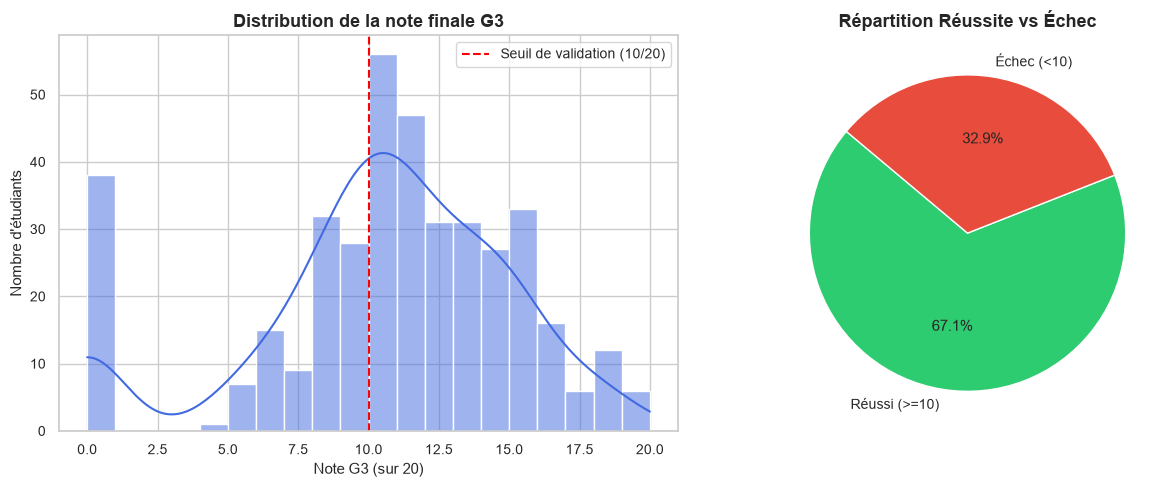

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Distribution des notes G3
sns.histplot(df_raw['G3'], bins=20, kde=True, color='royalblue', ax=ax1)
ax1.axvline(10, color='red', linestyle='--', label='Seuil de validation (10/20)')
ax1.set_title("Distribution de la note finale G3")
ax1.set_xlabel("Note G3 (sur 20)")
ax1.set_ylabel("Nombre d'étudiants")
ax1.legend()

# Distribution binaire du statut de réussite
df_raw['passed'] = (df_raw['G3'] >= 10).map({True: 'Réussi (>=10)', False: 'Échec (<10)'})
passed_counts = df_raw['passed'].value_counts()
ax2.pie(passed_counts, labels=passed_counts.index, autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'], startangle=140)
ax2.set_title("Répartition Réussite vs Échec")

plt.show()

## 4. Analyse des habitudes d'étude et antécédents scolaires
Facteurs clés à analyser :
- **Temps d'étude hebdomadaire** (`studytime` : 1 = <2h, 2 = 2-5h, 3 = 5-10h, 4 = >10h)
- **Échecs passés** (`failures` : 0 à 4)
- **Absences scolaires** (`absences`)
- **Soutien scolaire supplémentaire** (`schoolsup`)

2026-10-06 19:28:03,831 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


/var/folders/wc/2v1nt46504924xffw14h3wjh0000gn/T/ipykernel_51389/3317344033.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='studytime', y='G3', data=df_raw, palette='Blues', ax=axes[0, 0])
2026-10-06 19:28:03,834 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-06 19:28:03,853 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


/var/folders/wc/2v1nt46504924xffw14h3wjh0000gn/T/ipykernel_51389/3317344033.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='failures', y='G3', data=df_raw, palette='Reds', ax=axes[0, 1])
2026-10-06 19:28:03,855 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


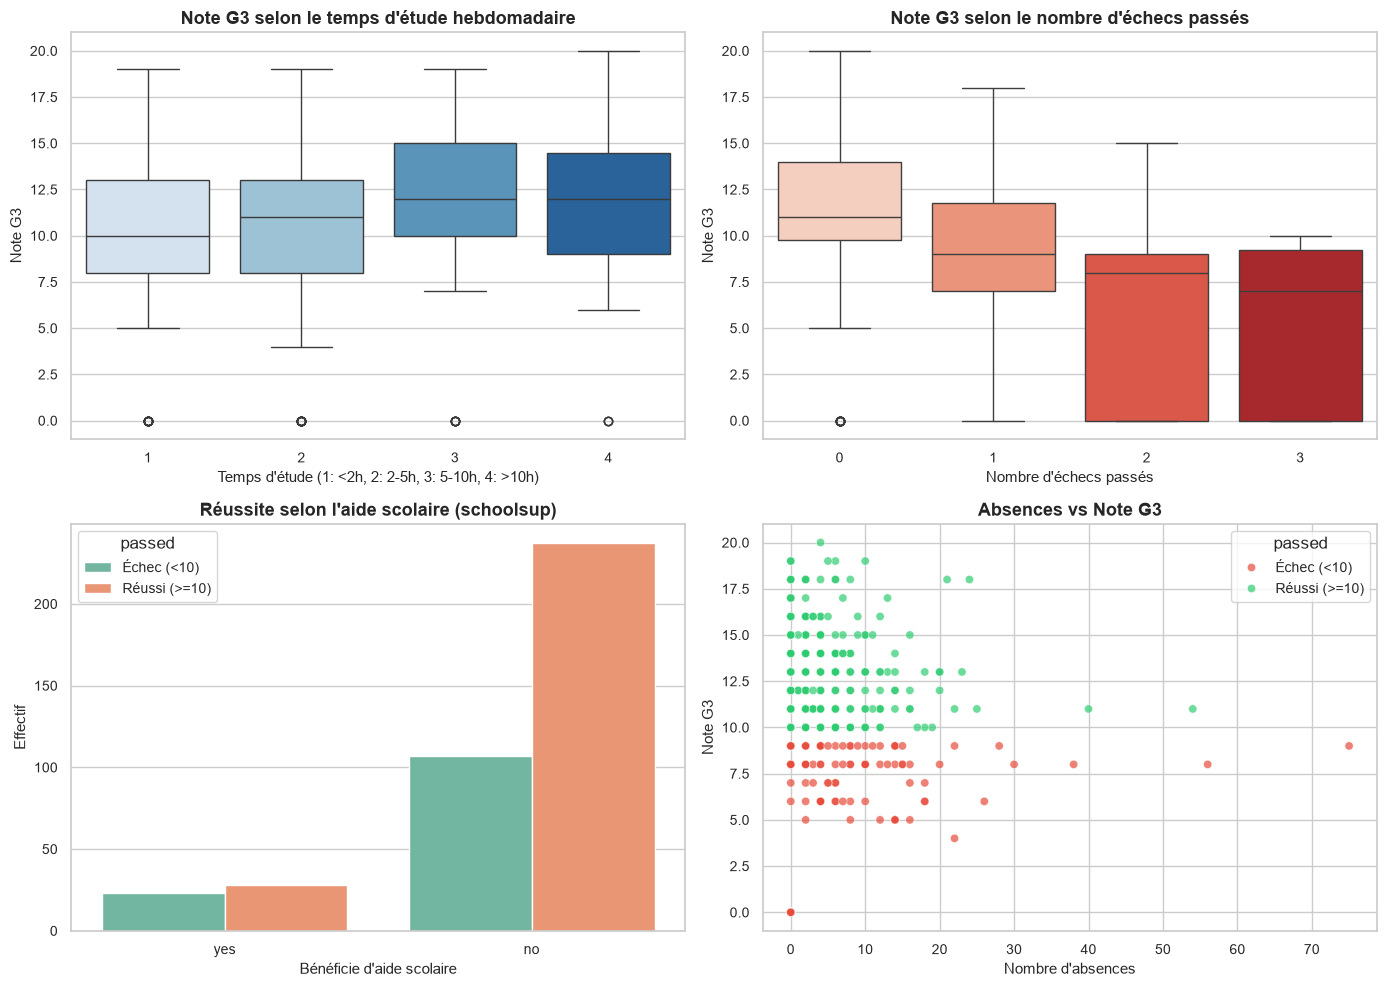

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Temps d'étude vs Note G3
sns.boxplot(x='studytime', y='G3', data=df_raw, palette='Blues', ax=axes[0, 0])
axes[0, 0].set_title("Note G3 selon le temps d'étude hebdomadaire")
axes[0, 0].set_xlabel("Temps d'étude (1: <2h, 2: 2-5h, 3: 5-10h, 4: >10h)")
axes[0, 0].set_ylabel("Note G3")

# Échecs scolaires passés vs G3
sns.boxplot(x='failures', y='G3', data=df_raw, palette='Reds', ax=axes[0, 1])
axes[0, 1].set_title("Note G3 selon le nombre d'échecs passés")
axes[0, 1].set_xlabel("Nombre d'échecs passés")
axes[0, 1].set_ylabel("Note G3")

# Taux de réussite selon le soutien scolaire (schoolsup)
sns.countplot(x='schoolsup', hue='passed', data=df_raw, palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title("Réussite selon l'aide scolaire (schoolsup)")
axes[1, 0].set_xlabel("Bénéficie d'aide scolaire")
axes[1, 0].set_ylabel("Effectif")

# Absences vs G3 avec distinction réussite/échec
sns.scatterplot(x='absences', y='G3', hue='passed', alpha=0.7, data=df_raw, palette={'Réussi (>=10)': '#2ecc71', 'Échec (<10)': '#e74c3c'}, ax=axes[1, 1])
axes[1, 1].set_title("Absences vs Note G3")
axes[1, 1].set_xlabel("Nombre d'absences")
axes[1, 1].set_ylabel("Note G3")

plt.tight_layout()
plt.show()

## 5. Habitudes de vie, cadre familial et consommation d'alcool
- `Dalc` (Workday alcohol consumption, 1-5) & `Walc` (Weekend alcohol consumption, 1-5)
- `Medu` & `Fedu` : Niveau d'instruction des parents (0 à 4)

2026-10-06 19:28:04,096 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


/var/folders/wc/2v1nt46504924xffw14h3wjh0000gn/T/ipykernel_51389/2881128107.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Walc', y='G3', data=df_raw, palette='Oranges', ax=ax1)
2026-10-06 19:28:04,099 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-06 19:28:04,122 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


/var/folders/wc/2v1nt46504924xffw14h3wjh0000gn/T/ipykernel_51389/2881128107.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Medu', y='G3', data=df_raw, palette='Purples', ax=ax2)
2026-10-06 19:28:04,124 - INFO - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


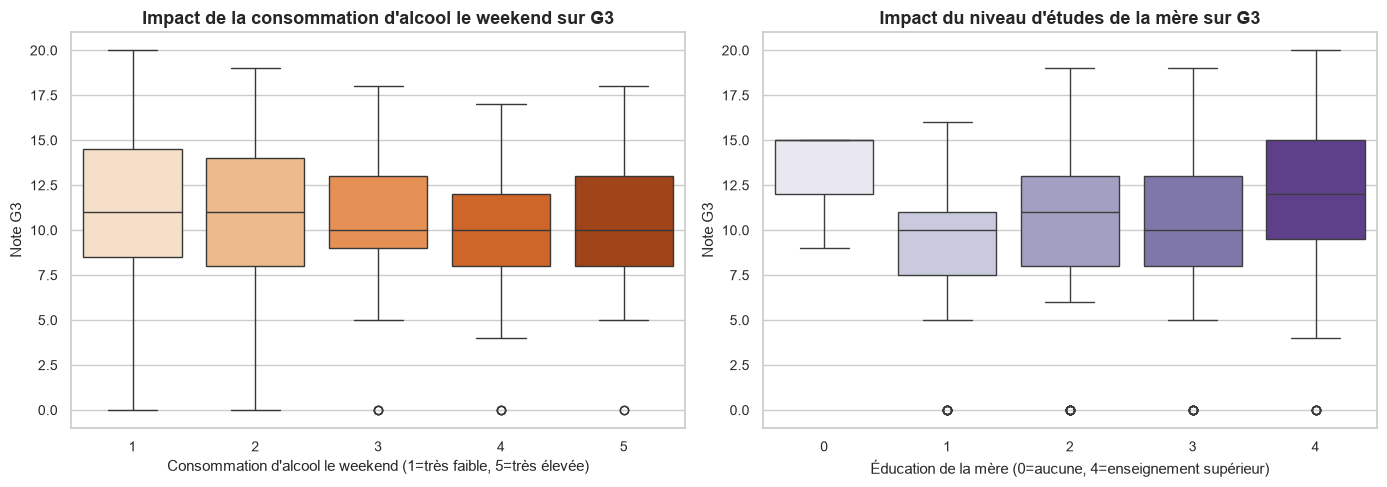

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Alcool le weekend vs Note G3
sns.boxplot(x='Walc', y='G3', data=df_raw, palette='Oranges', ax=ax1)
ax1.set_title("Impact de la consommation d'alcool le weekend sur G3")
ax1.set_xlabel("Consommation d'alcool le weekend (1=très faible, 5=très élevée)")
ax1.set_ylabel("Note G3")

# Éducation de la mère vs G3
sns.boxplot(x='Medu', y='G3', data=df_raw, palette='Purples', ax=ax2)
ax2.set_title("Impact du niveau d'études de la mère sur G3")
ax2.set_xlabel("Éducation de la mère (0=aucune, 4=enseignement supérieur)")
ax2.set_ylabel("Note G3")

plt.show()

## 6. Matrice de corrélation des variables quantitatives

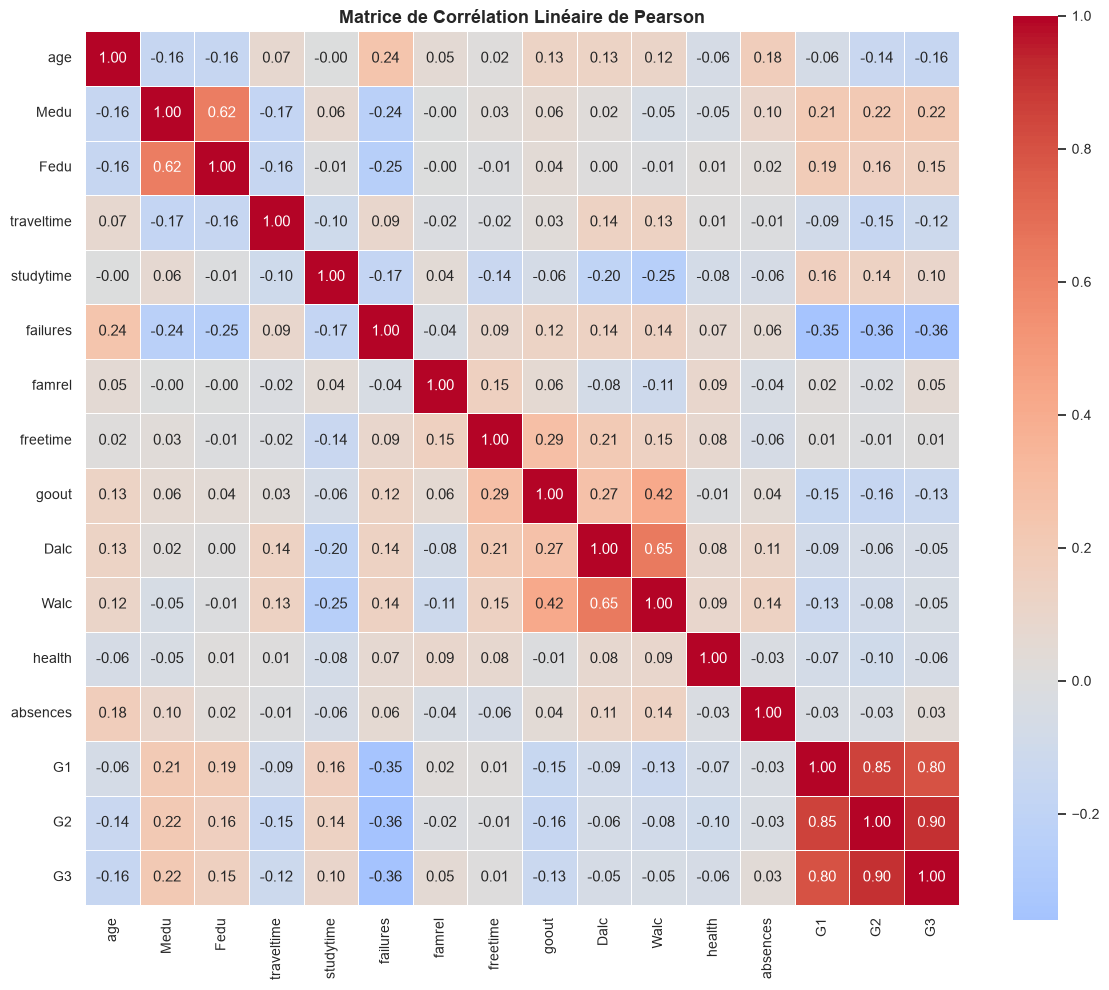

In [7]:
numeric_df = df_raw.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0, square=True, linewidths=0.5)
plt.title("Matrice de Corrélation Linéaire de Pearson")
plt.show()

## 7. Synthèse des constats de l'EDA
1. **Déséquilibre de classe modéré** : ~67% de réussite contre ~33% d'échec. Un découpage stratifié (*Stratified Train/Test Split*) et des métriques pondérées ($F1_{weighted}$, $ROC\text{-}AUC$) sont indispensables.
2. **Facteurs négatifs les plus influents** : L'historique des échecs antérieurs (`failures`) est le prédicteur négatif le plus fort, suivi d'une forte consommation d'alcool le weekend (`Walc`).
3. **Facteurs positifs** : Le niveau d'études des parents (`Medu`, `Fedu`), l'accès à internet et le temps d'étude hebdomadaire (`studytime`) favorisent significativement les résultats.
4. **Intégrité du dataset** : Aucune valeur manquante détectée dans les données brutes, mais une imputation défensive (`SimpleImputer`) doit être maintenue dans les pipelines Scikit-Learn pour la robustesse en production.